# Bank Loan Analysis Report

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')
%matplotlib inline
import plotly.express as px        #this creates interactive advance charts for scatterplot,line chart or area chart

In [2]:
df = pd.read_csv("C:/Users/Yogesh/Downloads/financial_loan_1.csv")      ##copy the file path
df.head()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
0,1077430,GA,INDIVIDUAL,< 1 year,Ryder,C,RENT,11-02-2021,13-09-2021,13-04-2021,...,C4,60 months,Source Verified,30000.0,0.0100,59.83,0.1527,2500,4,1009
1,1072053,CA,INDIVIDUAL,9 years,MKC Accounting,E,RENT,01-01-2021,14-12-2021,15-01-2021,...,E1,36 months,Source Verified,48000.0,0.0535,109.43,0.1864,3000,4,3939
2,1069243,CA,INDIVIDUAL,4 years,Chemat Technology Inc,C,RENT,05-01-2021,12-12-2021,09-01-2021,...,C5,36 months,Not Verified,50000.0,0.2088,421.65,0.1596,12000,11,3522
3,1041756,TX,INDIVIDUAL,< 1 year,barnes distribution,B,MORTGAGE,25-02-2021,12-12-2021,12-03-2021,...,B2,60 months,Source Verified,42000.0,0.0540,97.06,0.1065,4500,9,4911
4,1068350,IL,INDIVIDUAL,10+ years,J&J Steel Inc,A,MORTGAGE,01-01-2021,14-12-2021,15-01-2021,...,A1,36 months,Verified,83000.0,0.0231,106.53,0.0603,3500,28,3835


In [3]:
df.tail()

,id,address_state,application_type,emp_length,emp_title,grade,home_ownership,issue_date,last_credit_pull_date,last_payment_date,...,sub_grade,term,verification_status,annual_income,dti,installment,int_rate,loan_amount,total_acc,total_payment
38571,803452,NJ,INDIVIDUAL,< 1 year,Joseph M Sanzari Company,C,MORTGAGE,11-07-2021,16-05-2021,16-05-2021,...,C1,60 months,Verified,100000.0,0.1986,551.64,0.1299,24250,33,31946
38572,970377,NY,INDIVIDUAL,8 years,Swat Fame,C,RENT,11-10-2021,16-04-2021,16-05-2021,...,C1,60 months,Verified,50000.0,0.0458,579.72,0.1349,25200,18,31870
38573,875376,CA,INDIVIDUAL,5 years,Anaheim Regional Medical Center,D,RENT,11-09-2021,16-05-2021,16-05-2021,...,D5,60 months,Verified,65000.0,0.1734,627.93,0.1749,25000,20,35721
38574,972997,NY,INDIVIDUAL,5 years,Brooklyn Radiology,D,RENT,11-10-2021,16-05-2021,16-05-2021,...,D5,60 months,Verified,368000.0,0.0009,612.72,0.1825,24000,9,33677
38575,682952,NY,INDIVIDUAL,4 years,Allen Edmonds,F,RENT,11-07-2021,16-05-2021,16-05-2021,...,F3,60 months,Verified,80000.0,0.0600,486.86,0.2099,18000,7,27679


## Metadata of data

In [4]:
print("No of Rows:",df.shape[0])

No of Rows: 38576


In [5]:
print("No of Columns:",df.shape[1])

No of Columns: 24


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 38576 entries, 0 to 38575
Data columns (total 24 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   id                     38576 non-null  int64  
 1   address_state          38576 non-null  object 
 2   application_type       38576 non-null  object 
 3   emp_length             38576 non-null  object 
 4   emp_title              37138 non-null  object 
 5   grade                  38576 non-null  object 
 6   home_ownership         38576 non-null  object 
 7   issue_date             38576 non-null  object 
 8   last_credit_pull_date  38576 non-null  object 
 9   last_payment_date      38576 non-null  object 
 10  loan_status            38576 non-null  object 
 11  next_payment_date      38576 non-null  object 
 12  member_id              38576 non-null  int64  
 13  purpose                38576 non-null  object 
 14  sub_grade              38576 non-null  object 
 15  te

## Data Types

In [7]:
df.dtypes

id                         int64
address_state             object
application_type          object
emp_length                object
emp_title                 object
grade                     object
home_ownership            object
issue_date                object
last_credit_pull_date     object
last_payment_date         object
loan_status               object
next_payment_date         object
member_id                  int64
purpose                   object
sub_grade                 object
term                      object
verification_status       object
annual_income            float64
dti                      float64
installment              float64
int_rate                 float64
loan_amount                int64
total_acc                  int64
total_payment              int64
dtype: object

In [8]:
date_cols = [
    "issue_date",
    "last_credit_pull_date",
    "last_payment_date",
    "next_payment_date"
]

# Convert them to datetime
df[date_cols] = df[date_cols].apply(
    lambda col: pd.to_datetime(col, errors="coerce", format="%d-%m-%Y")
)

# lambda col: pd.to_datetime(col, errors="coerce", format="%d-%m-%Y") : is an inline function that converts each column’s values into proper datetime64 objects.
# errors="coerce" - means: if a value doesn’t match the expected format, it becomes NaT (Not a Time, i.e. missing datetime).


print(df[date_cols].dtypes)

issue_date               datetime64[ns]
last_credit_pull_date    datetime64[ns]
last_payment_date        datetime64[ns]
next_payment_date        datetime64[ns]
dtype: object


In [9]:
df.dtypes

id                                int64
address_state                    object
application_type                 object
emp_length                       object
emp_title                        object
grade                            object
home_ownership                   object
issue_date               datetime64[ns]
last_credit_pull_date    datetime64[ns]
last_payment_date        datetime64[ns]
loan_status                      object
next_payment_date        datetime64[ns]
member_id                         int64
purpose                          object
sub_grade                        object
term                             object
verification_status              object
annual_income                   float64
dti                             float64
installment                     float64
int_rate                        float64
loan_amount                       int64
total_acc                         int64
total_payment                     int64
dtype: object

In [10]:
df.describe().T

,count,mean,min,25%,50%,75%,max,std
id,38576.0,681037.061385,54734.0,513517.0,662728.0,836506.0,1077501.0,211324.578218
issue_date,38576,2021-07-16 02:31:35.562007040,2021-01-01 00:00:00,2021-04-11 00:00:00,2021-07-11 00:00:00,2021-10-11 00:00:00,2021-12-12 00:00:00,NaN
last_credit_pull_date,38576,2021-06-08 13:36:34.193280512,2021-01-08 00:00:00,2021-04-15 00:00:00,2021-05-16 00:00:00,2021-08-13 00:00:00,2022-01-20 00:00:00,NaN
last_payment_date,38576,2021-06-26 09:52:08.909166080,2021-01-08 00:00:00,2021-03-16 00:00:00,2021-06-14 00:00:00,2021-09-15 00:00:00,2021-12-15 00:00:00,NaN
next_payment_date,38576,2021-07-26 20:42:20.605557760,2021-02-08 00:00:00,2021-04-16 00:00:00,2021-07-14 00:00:00,2021-10-15 00:00:00,2022-01-15 00:00:00,NaN
member_id,38576.0,847651.506299,70699.0,662978.75,847356.5,1045652.5,1314167.0,266810.45686
annual_income,38576.0,69644.54031,4000.0,41500.0,60000.0,83200.5,6000000.0,64293.681045
dti,38576.0,0.133274,0.0,0.0821,0.1342,0.1859,0.2999,0.066662
installment,38576.0,326.862965,15.69,168.45,283.045,434.4425,1305.19,209.092
int_rate,38576.0,0.120488,0.0542,0.0932,0.1186,0.1459,0.2459,0.037164


## Total Loan Application

In [11]:
total_loan_application = df['id'].count()
print('Total Loan Applications :',total_loan_application)

Total Loan Applications : 38576


## MTD Total Loan Application

In [12]:
latest_issue_date = df['issue_date'].max()
latest_year = latest_issue_date.year
latest_month = latest_issue_date.month

mtd_data = df[(df['issue_date'].dt.year == latest_year) & (df['issue_date'].dt.month == latest_month)]

mtd_loan_application = mtd_data['id'].count()

print(f"MTD Total Loan Application(for {latest_issue_date.strftime('%B %Y')}):{mtd_loan_application}")

MTD Total Loan Application(for December 2021):4314


## Total Funded Amount

In [13]:
total_funded_amount = df['loan_amount'].sum()
print('Total Funded Amount :',total_funded_amount)

Total Funded Amount : 435757075


In [14]:
total_funded_amount = df['loan_amount'].sum()
total_funded_amount_millions = total_funded_amount / 1000000
print('Total Funded Amount : ${:.2f}M'.format(total_funded_amount_millions))

Total Funded Amount : $435.76M


## MTD Total Funded Amount

In [15]:
latest_issue_date = df['issue_date'].max()
latest_year = latest_issue_date.year
latest_month = latest_issue_date.month

mtd_data = df[(df['issue_date'].dt.year == latest_year) & (df['issue_date'].dt.month == latest_month)]

mtd_total_funded_amount = mtd_data['loan_amount'].sum()
mtd_total_funded_amount_millions = mtd_total_funded_amount/1000000

print('MTD Total Funded Amount: ${:.2f}M'.format(mtd_total_funded_amount_millions))

MTD Total Funded Amount: $53.98M


## Total Amount Received

In [16]:
total_amount_received = df['total_payment'].sum()
total_amount_received_millions = total_amount_received / 1000000
print('Total Amount Received : ${:.2f}M'.format(total_amount_received_millions))

Total Amount Received : $473.07M


## MTD Total Amount Received

In [17]:
latest_issue_date = df['issue_date'].max()
latest_year = latest_issue_date.year
latest_month = latest_issue_date.month

mtd_data = df[(df['issue_date'].dt.year == latest_year) & (df['issue_date'].dt.month == latest_month)]

mtd_total_amount_received = mtd_data['total_payment'].sum()
mtd_total_amount_received_millions = mtd_total_amount_received/1000000

print('MTD Total Amount Received: ${:.2f}M'.format(mtd_total_amount_received_millions))

MTD Total Amount Received: $58.07M


## Average Interst Rate

In [18]:
avg_interest_rate = df['int_rate'].mean()*100
print('Average Interst Rate : {:.2f}%'.format(avg_interest_rate))

Average Interst Rate : 12.05%


## Avg Debt-to-Income Ratio (DTI)

In [19]:
avg_dti = df['dti'].mean()*100
print('Average DTI : {:.2f}%'.format(avg_dti))

Average DTI : 13.33%


## Good Loan Metrics

In [20]:
good_loans = df[df['loan_status'].isin(['Fully Paid','Current'])]

total_loan_apps = df['id'].count()
good_loan_apps = good_loans['id'].count()

good_loan_funded_amount = good_loans['loan_amount'].sum()
good_loan_received = good_loans['total_payment'].sum()

good_loan_funded_amount_millions = good_loan_funded_amount/1000000
good_loan_received_millions = good_loan_received/1000000

good_loan_percentage = (good_loan_apps/total_loan_apps) * 100

print("Good Loan Applications :",good_loan_apps)
print("Good Loan Funded Amount (in Millions) : ${:.2f}M".format(good_loan_funded_amount_millions))
print("Good Loan Received (in Millions) : ${:.2f}M".format(good_loan_received_millions))
print("Percentage of Good Loan : {:.2f}%".format(good_loan_percentage))

Good Loan Applications : 33243
Good Loan Funded Amount (in Millions) : $370.22M
Good Loan Received (in Millions) : $435.79M
Percentage of Good Loan : 86.18%


## Bad Loan Materics

In [21]:
bad_loans = df[df['loan_status'].isin(['Charged Off'])]

total_loan_apps = df['id'].count()
bad_loan_apps = bad_loans['id'].count()

bad_loan_funded_amount = bad_loans['loan_amount'].sum()
bad_loan_received = bad_loans['total_payment'].sum()

bad_loan_funded_amount_millions = bad_loan_funded_amount/1000000
bad_loan_received_millions = bad_loan_received/1000000

bad_loan_percentage = (bad_loan_apps/total_loan_apps) * 100

print("Bad Loan Applications :",bad_loan_apps)
print("Bad Loan Funded Amount (in Millions) : ${:.2f}M".format(bad_loan_funded_amount_millions))
print("Bad Loan Received (in Millions) : ${:.2f}M".format(bad_loan_received_millions))
print("Percentage of Bad Loan : {:.2f}%".format(bad_loan_percentage))

Bad Loan Applications : 5333
Bad Loan Funded Amount (in Millions) : $65.53M
Bad Loan Received (in Millions) : $37.28M
Percentage of Bad Loan : 13.82%


## Monthly Trends by Issue Date for Total Funded Amount

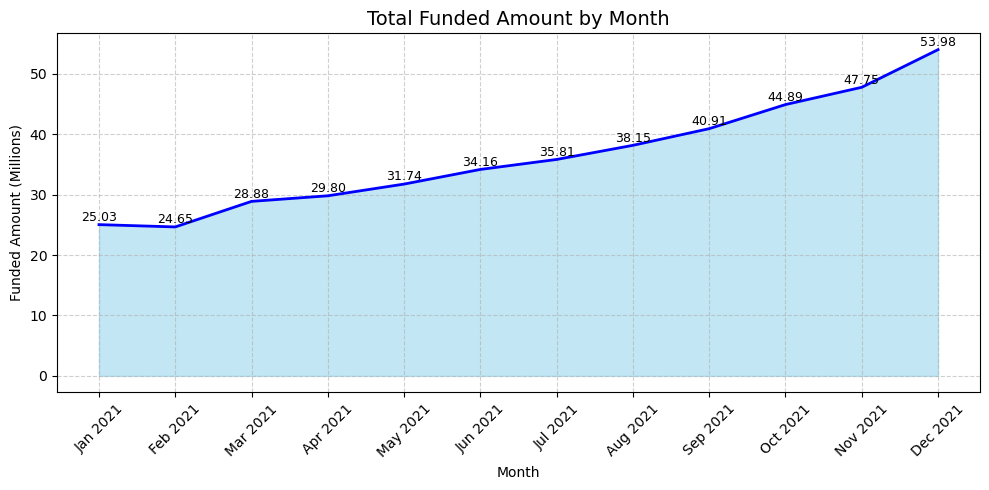

In [27]:
monthly_funded = (
    df.sort_values('issue_date')
      .assign(month_name=lambda x: x['issue_date'].dt.strftime('%b %Y'))
      .groupby('month_name',sort = False)['loan_amount']
      .sum()
      .div(1000000)
      .reset_index(name='loan_amount_millions')
)

plt.figure(figsize=(10,5))
plt.fill_between(monthly_funded['month_name'], monthly_funded['loan_amount_millions'], color='skyblue',alpha = 0.5)
plt.plot(monthly_funded['month_name'], monthly_funded['loan_amount_millions'],color = 'blue',linewidth=2)

for i,row in monthly_funded.iterrows():
    plt.text(i,row['loan_amount_millions'] + 0.1, f"{row['loan_amount_millions']:.2f}",
             ha='center',va='bottom',fontsize=9,rotation=0,color='black')

plt.title('Total Funded Amount by Month' ,fontsize=14)
plt.xlabel('Month')
plt.ylabel('Funded Amount (Millions)')
plt.xticks(ticks=range(len(monthly_funded)),label=monthly_funded['month_name'],rotation = 45)
plt.grid(True, linestyle='--',alpha=0.6)
plt.tight_layout()
plt.show()

## Monthly Trends by Issue Date for Total Amount Received

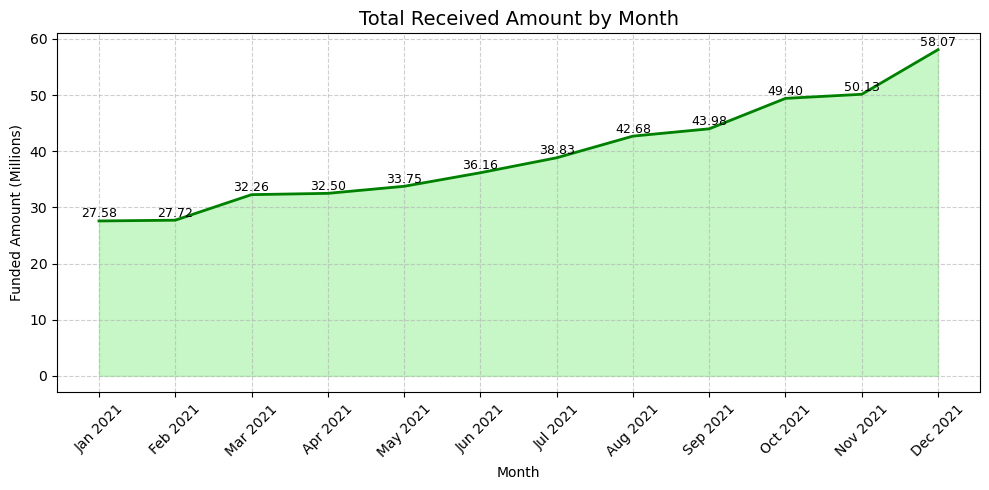

In [31]:
monthly_received = (
    df.sort_values('issue_date')
      .assign(month_name=lambda x: x['issue_date'].dt.strftime('%b %Y'))
      .groupby('month_name',sort = False)['total_payment']
      .sum()
      .div(1000000)
      .reset_index(name='received_amount_millions')
)

plt.figure(figsize=(10,5))
plt.fill_between(monthly_received['month_name'], monthly_received['received_amount_millions'], color='lightgreen',alpha = 0.5)
plt.plot(monthly_received['month_name'], monthly_received['received_amount_millions'],color = 'green',linewidth=2)

for i,row in monthly_received.iterrows():
    plt.text(i,row['received_amount_millions'] + 0.1, f"{row['received_amount_millions']:.2f}",
             ha='center',va='bottom',fontsize=9,rotation=0,color='black')

plt.title('Total Received Amount by Month' ,fontsize=14)
plt.xlabel('Month')
plt.ylabel('Funded Amount (Millions)')
plt.xticks(ticks=range(len(monthly_funded)),label=monthly_funded['month_name'],rotation = 45)
plt.grid(True, linestyle='--',alpha=0.6)
plt.tight_layout()
plt.show()

## Monthly Trends by Issue Date for Total Loan Applications

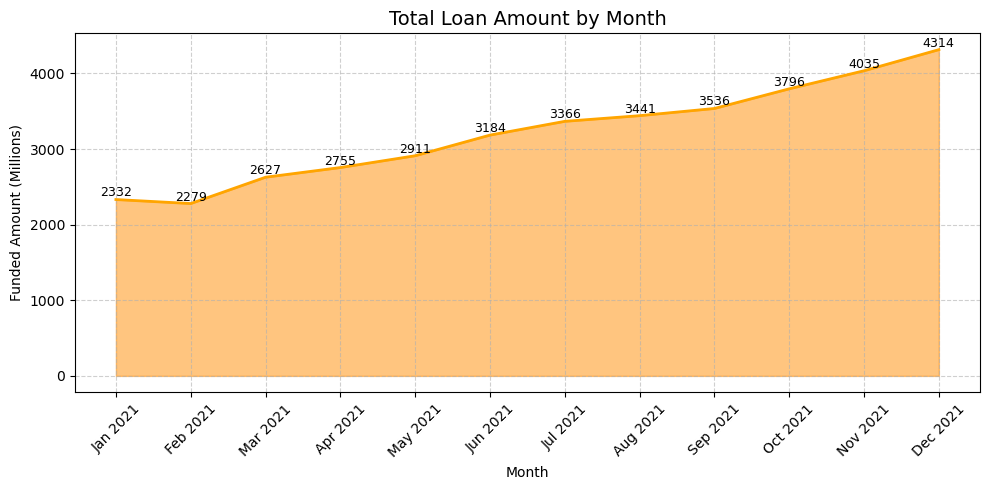

In [38]:
monthly_applications = (
    df.sort_values('issue_date')
      .assign(month_name=lambda x: x['issue_date'].dt.strftime('%b %Y'))
      .groupby('month_name',sort = False)['id']
      .count()
      .reset_index(name='loan_application_count')
)

plt.figure(figsize=(10,5))
plt.fill_between(monthly_applications['month_name'], monthly_applications['loan_application_count'], color='darkorange',alpha = 0.5)
plt.plot(monthly_applications['month_name'], monthly_applications['loan_application_count'],color = 'orange',linewidth=2)

for i,row in monthly_applications.iterrows():
    plt.text(i,row['loan_application_count'] + 0.5, f"{row['loan_application_count']}",
             ha='center',va='bottom',fontsize=9,rotation=0,color='black')

plt.title('Total Loan Amount by Month' ,fontsize=14)
plt.xlabel('Month')
plt.ylabel('Funded Amount (Millions)')
plt.xticks(ticks=range(len(monthly_funded)),label=monthly_funded['month_name'],rotation = 45)
plt.grid(True, linestyle='--',alpha=0.6)
plt.tight_layout()
plt.show()

## Regional Analysis by State for Total Funded Amount

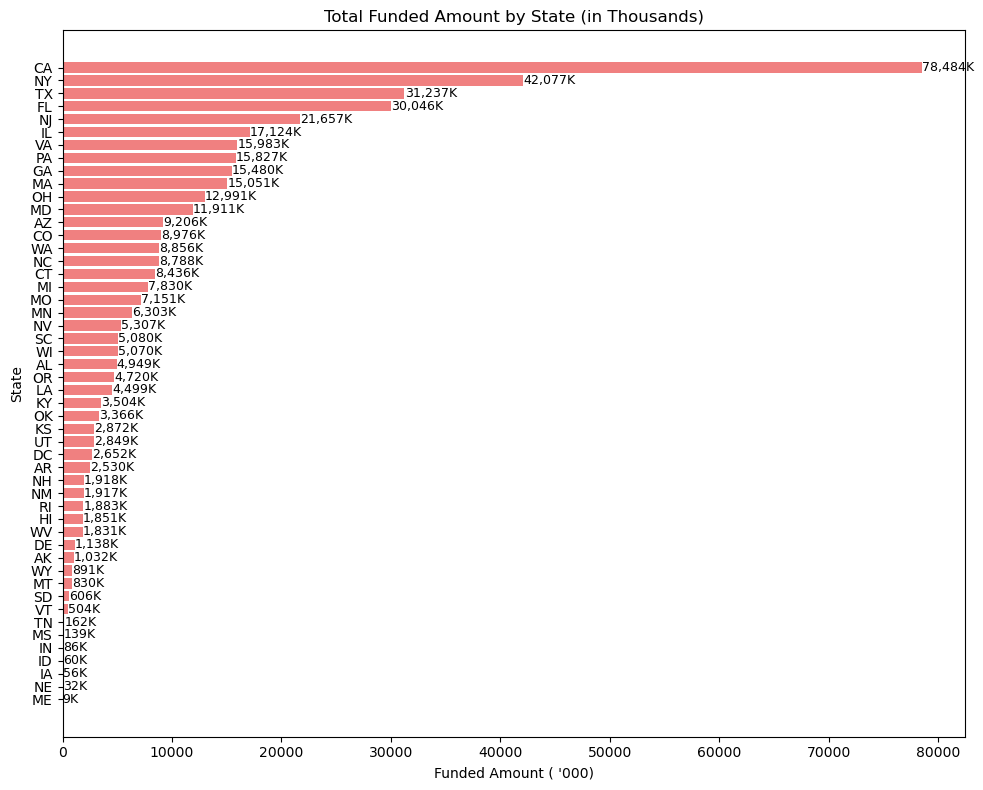

In [48]:
state_funding = df.groupby('address_state')['loan_amount'].sum().sort_values(ascending = True)
state_funding_thousands = state_funding / 1000

plt.figure(figsize = (10,8))
bars = plt.barh(state_funding_thousands.index,state_funding_thousands.values,color = 'lightcoral')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 10, bar.get_y() + bar.get_height()/2,
             f'{width:,.0f}K',va='center',fontsize=9)

plt.title('Total Funded Amount by State (in Thousands)')
plt.xlabel('Funded Amount ( \'000)')
plt.ylabel('State')
plt.tight_layout()
plt.show()

## Regional Analysis by State for Total Amount Received

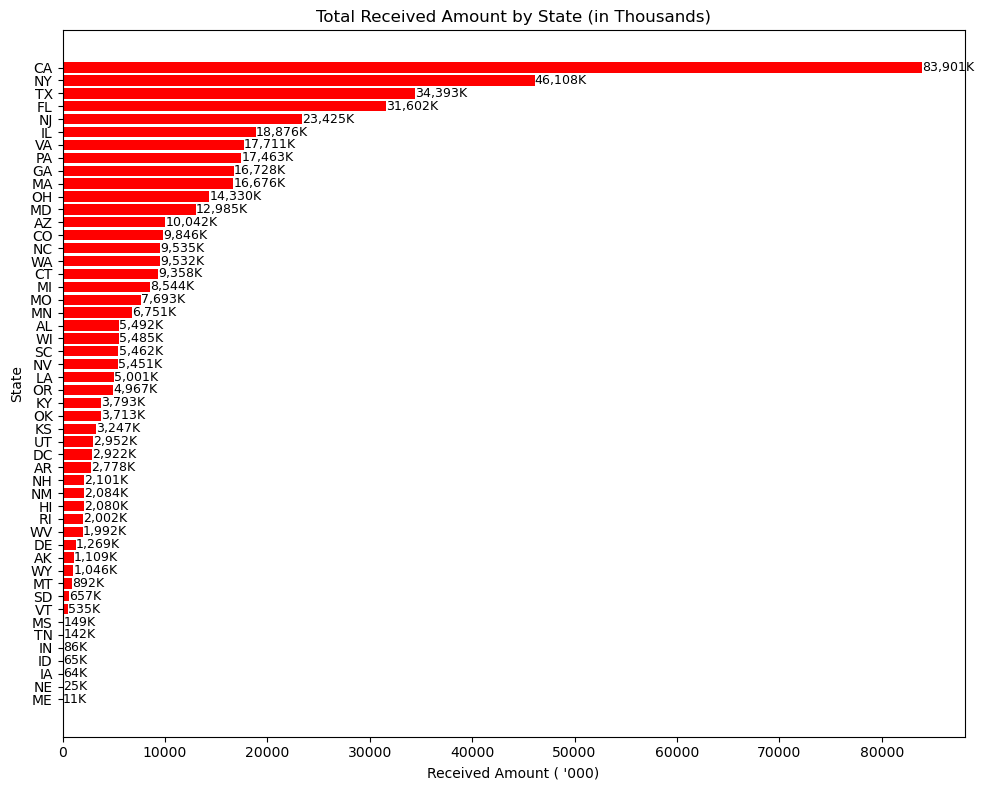

In [49]:
state_receiving = df.groupby('address_state')['total_payment'].sum().sort_values(ascending = True)
state_receiving_thousands = state_receiving / 1000

plt.figure(figsize = (10,8))
bars = plt.barh(state_receiving_thousands.index,state_receiving_thousands.values,color = 'red')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 10, bar.get_y() + bar.get_height()/2,
             f'{width:,.0f}K',va='center',fontsize=9)

plt.title('Total Received Amount by State (in Thousands)')
plt.xlabel('Received Amount ( \'000)')
plt.ylabel('State')
plt.tight_layout()
plt.show()

## Regional Analysis by State for Total Loan Applications

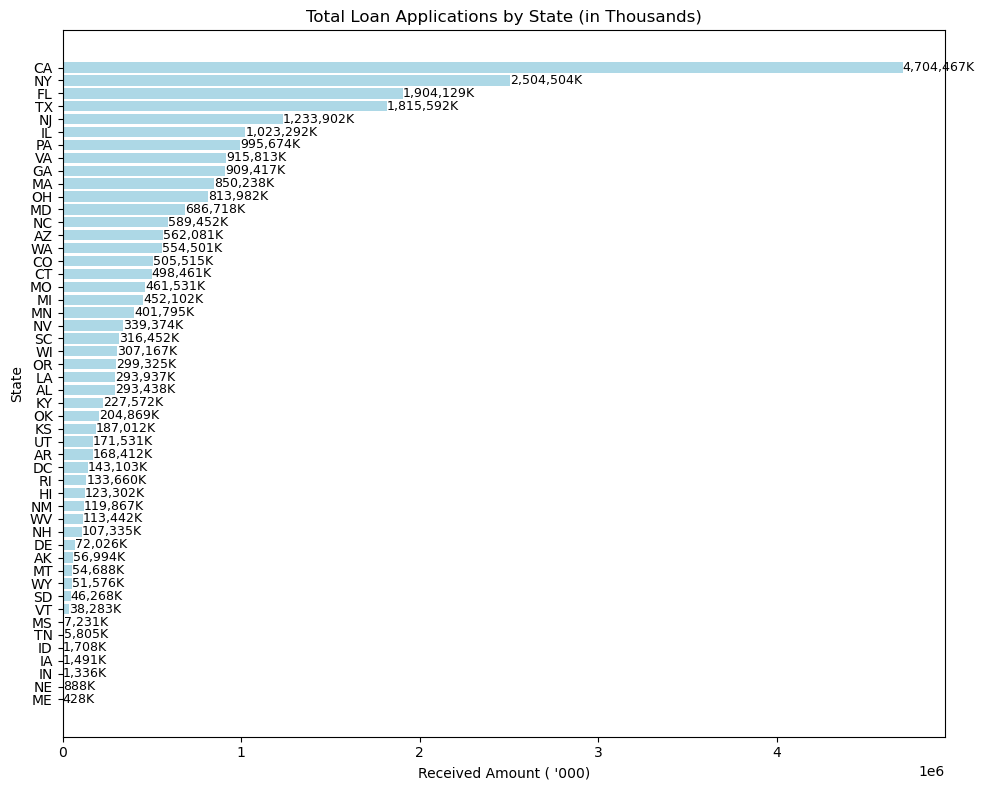

In [57]:
state_application = df.groupby('address_state')['id'].sum().sort_values(ascending = True)
state_application_thousands = state_application / 1000

plt.figure(figsize = (10,8))
bars = plt.barh(state_application_thousands.index,state_application_thousands.values,color = 'lightblue')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 10, bar.get_y() + bar.get_height()/2,
             f'{width:,.0f}K',va='center',fontsize=9)

plt.title('Total Loan Applications by State (in Thousands)')
plt.xlabel('Received Amount ( \'000)')
plt.ylabel('State')
plt.tight_layout()
plt.show()

## Loan Term Analysis by Total Funded Amount

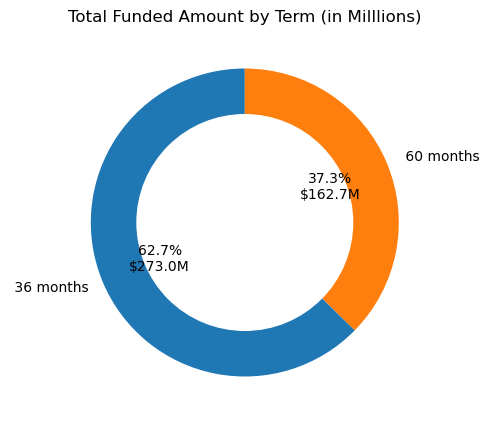

In [43]:
term_funding_millions = df.groupby('term')['loan_amount'].sum()/1000000

plt.figure(figsize=(5,5))
plt.pie(
    term_funding_millions,
    labels = term_funding_millions.index,
    autopct = lambda p: f"{p:.1f}%\n${p*sum(term_funding_millions)/100:.1f}M",
    startangle = 90,
    wedgeprops={'width':0.4}
)
plt.gca().add_artist(plt.Circle((0,0),0.70,color='white'))
plt.title("Total Funded Amount by Term (in Milllions)")
plt.show()

## Loan Term Analysis by Total Received Amount

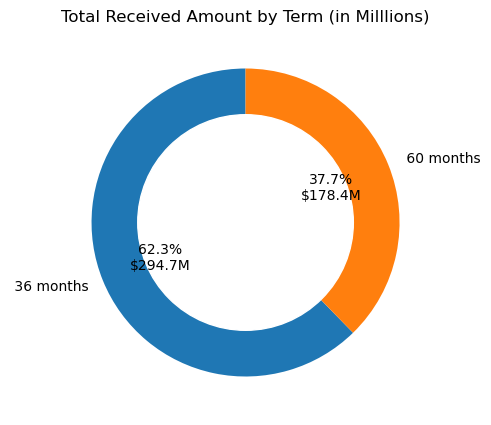

In [59]:
term_receiving_millions = df.groupby('term')['total_payment'].sum()/1000000

plt.figure(figsize=(5,5))
plt.pie(
    term_receiving_millions,
    labels = term_receiving_millions.index,
    autopct = lambda p: f"{p:.1f}%\n${p*sum(term_receiving_millions)/100:.1f}M",
    startangle = 90,
    wedgeprops={'width':0.4}
)
plt.gca().add_artist(plt.Circle((0,0),0.70,color='white'))
plt.title("Total Received Amount by Term (in Milllions)")
plt.show()

## Loan Term Analysis by Total Loan Application

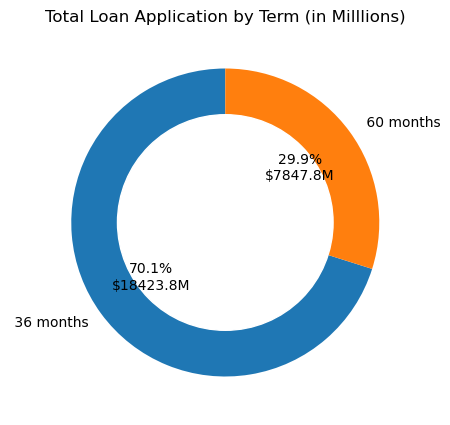

In [55]:
term_loan_apps = df.groupby('term')['id'].sum()/1000000

plt.figure(figsize=(5,5))
plt.pie(
    term_loan_apps,
    labels = term_loan_apps.index,
    autopct = lambda p: f"{p:.1f}%\n${p*sum(term_loan_apps)/100:.1f}M",
    startangle = 90,
    wedgeprops={'width':0.4}
)
plt.gca().add_artist(plt.Circle((0,0),0.70,color='white'))
plt.title("Total Loan Application by Term (in Milllions)")
plt.show()

## Employee Length by Total Funded Amount

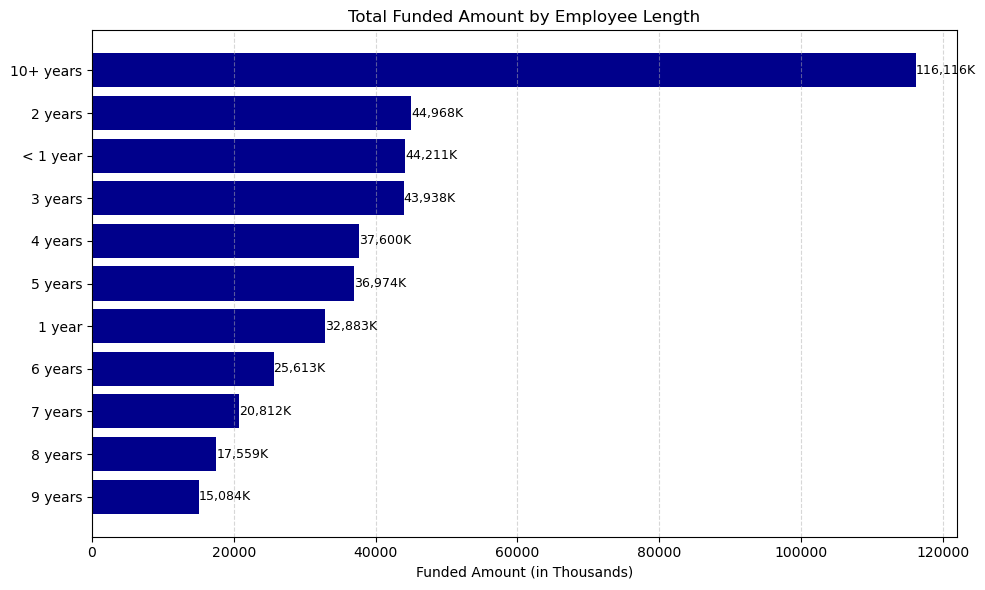

In [64]:
emp_funding = df.groupby('emp_length')['loan_amount'].sum().sort_values()/1000

plt.figure(figsize = (10,6))
bars = plt.barh(emp_funding.index,emp_funding,color = 'darkblue')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height()/2,
             f'{width:,.0f}K',va='center',fontsize=9)

plt.title('Total Funded Amount by Employee Length')
plt.xlabel('Funded Amount (in Thousands)')
plt.grid(axis='x',linestyle='--',alpha=0.5)
plt.tight_layout()
plt.show()

## Employee Length by Total Received Amount

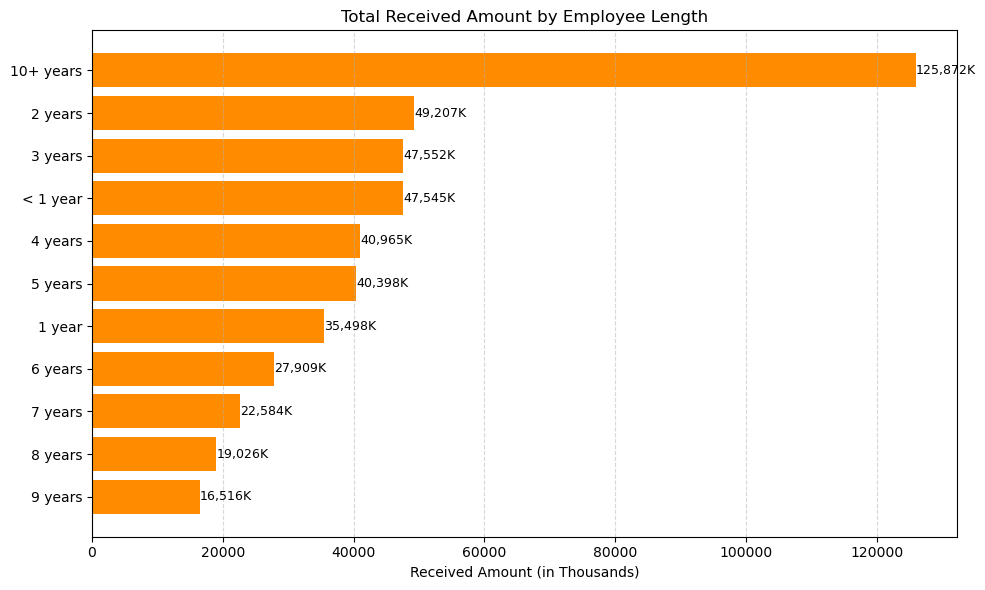

In [67]:
emp_receiving = df.groupby('emp_length')['total_payment'].sum().sort_values()/1000

plt.figure(figsize = (10,6))
bars = plt.barh(emp_receiving.index,emp_receiving,color = 'darkorange')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height()/2,
             f'{width:,.0f}K',va='center',fontsize=9)

plt.title('Total Received Amount by Employee Length')
plt.xlabel('Received Amount (in Thousands)')
plt.grid(axis='x',linestyle='--',alpha=0.5)
plt.tight_layout()
plt.show()

## Employee Length by Total Loan Application

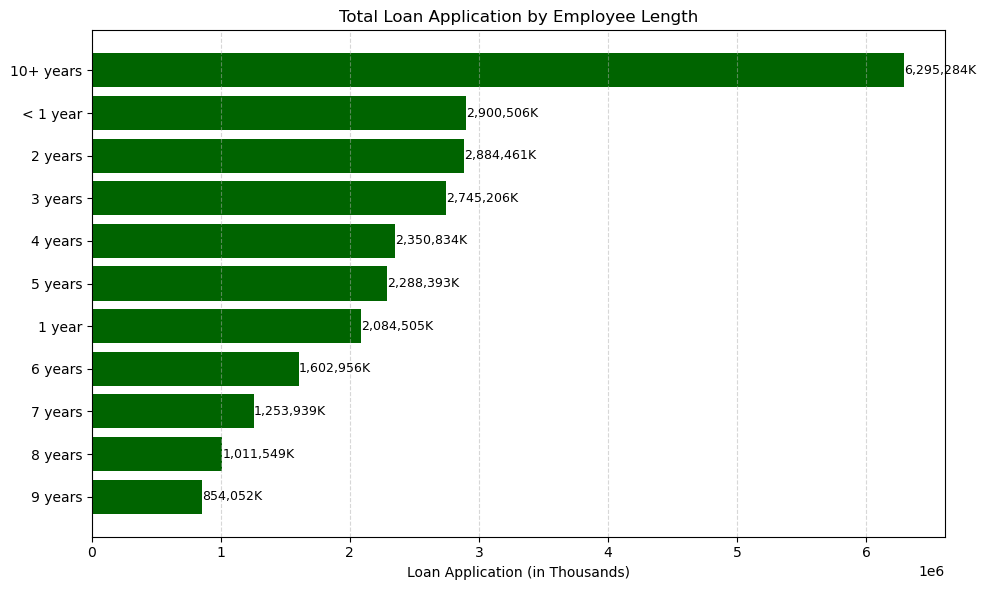

In [68]:
emp_apps = df.groupby('emp_length')['id'].sum().sort_values()/1000

plt.figure(figsize = (10,6))
bars = plt.barh(emp_apps.index,emp_apps,color = 'darkgreen')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 5, bar.get_y() + bar.get_height()/2,
             f'{width:,.0f}K',va='center',fontsize=9)

plt.title('Total Loan Application by Employee Length')
plt.xlabel('Loan Application (in Thousands)')
plt.grid(axis='x',linestyle='--',alpha=0.5)
plt.tight_layout()
plt.show()

## Loan Purpose by Total Funded Amount

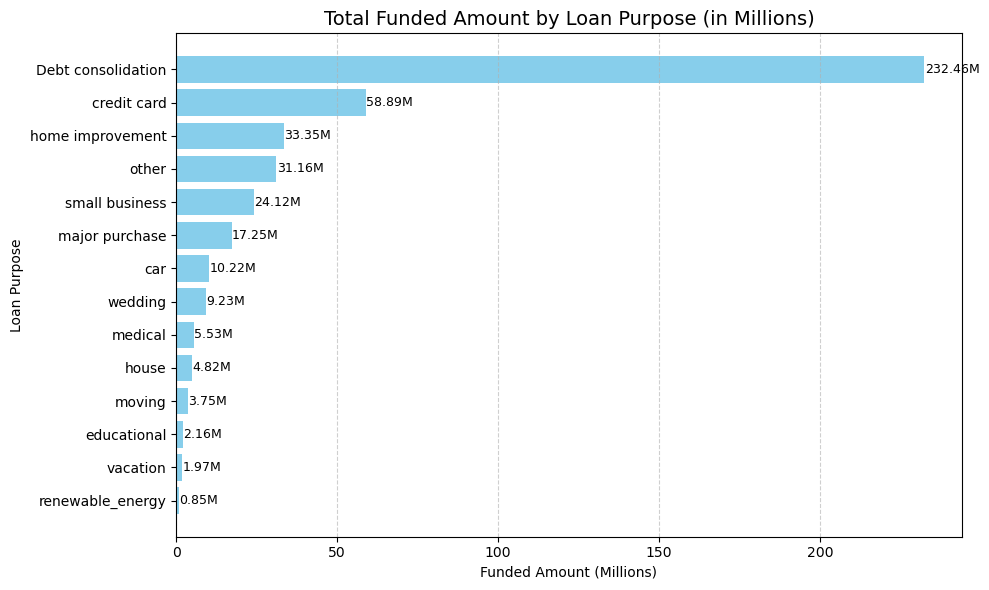

In [71]:
purpose_funding_millions = (df.groupby('purpose')['loan_amount'].sum().sort_values()/1000000)

plt.figure(figsize = (10,6))
bars = plt.barh(purpose_funding_millions.index,purpose_funding_millions.values,color = 'skyblue')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.1, bar.get_y() + bar.get_height()/2,
             f'{width:,.2f}M',va='center',fontsize=9)

plt.title('Total Funded Amount by Loan Purpose (in Millions)',fontsize = 14)
plt.xlabel('Funded Amount (Millions)')
plt.ylabel('Loan Purpose')
plt.grid(axis='x',linestyle='--',alpha=0.6)
plt.tight_layout()
plt.show()

## Loan Purpose by Total Received Amount

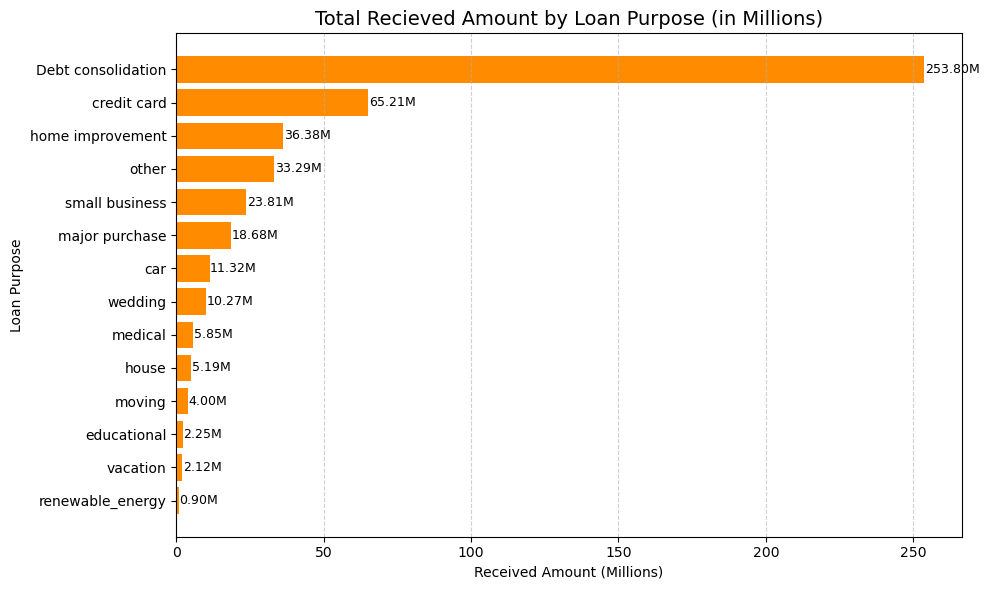

In [75]:
purpose_receiving_millions = (df.groupby('purpose')['total_payment'].sum().sort_values()/1000000)

plt.figure(figsize = (10,6))
bars = plt.barh(purpose_receiving_millions.index,purpose_receiving_millions.values,color = 'darkorange')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.1, bar.get_y() + bar.get_height()/2,
             f'{width:,.2f}M',va='center',fontsize=9)

plt.title('Total Recieved Amount by Loan Purpose (in Millions)',fontsize = 14)
plt.xlabel('Received Amount (Millions)')
plt.ylabel('Loan Purpose')
plt.grid(axis='x',linestyle='--',alpha=0.6)
plt.tight_layout()
plt.show()

## Loan Purpose by Total Loan Applications

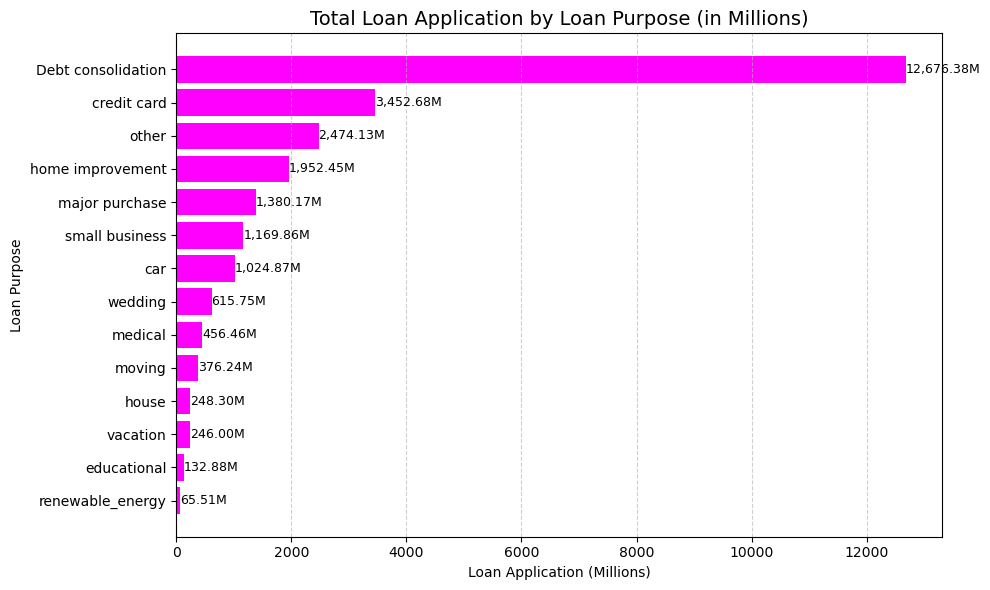

In [80]:
purpose_apps_millions = (df.groupby('purpose')['id'].sum().sort_values()/1000000)

plt.figure(figsize = (10,6))
bars = plt.barh(purpose_apps_millions.index,purpose_apps_millions.values,color = 'magenta')

for bar in bars:
    width = bar.get_width()
    plt.text(width + 0.1, bar.get_y() + bar.get_height()/2,
             f'{width:,.2f}M',va='center',fontsize=9)

plt.title('Total Loan Application by Loan Purpose (in Millions)',fontsize = 14)
plt.xlabel('Loan Application (Millions)')
plt.ylabel('Loan Purpose')
plt.grid(axis='x',linestyle='--',alpha=0.6)
plt.tight_layout()
plt.show()

## Home Ownership by Total Funded Amount

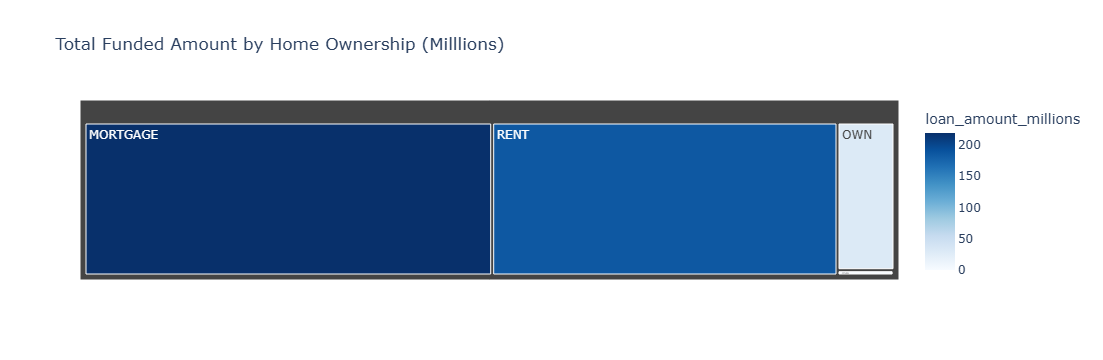

In [84]:
home_funding = df.groupby('home_ownership')['loan_amount'].sum().reset_index()
home_funding['loan_amount_millions'] = home_funding['loan_amount']/1000000

fig = px.treemap(
    home_funding,
    path=['home_ownership'],
    values='loan_amount_millions',
    color='loan_amount_millions',
    color_continuous_scale='Blues',
    title='Total Funded Amount by Home Ownership (Milllions)'
)
fig.show()

## Home Ownership by Total Receivced Amount

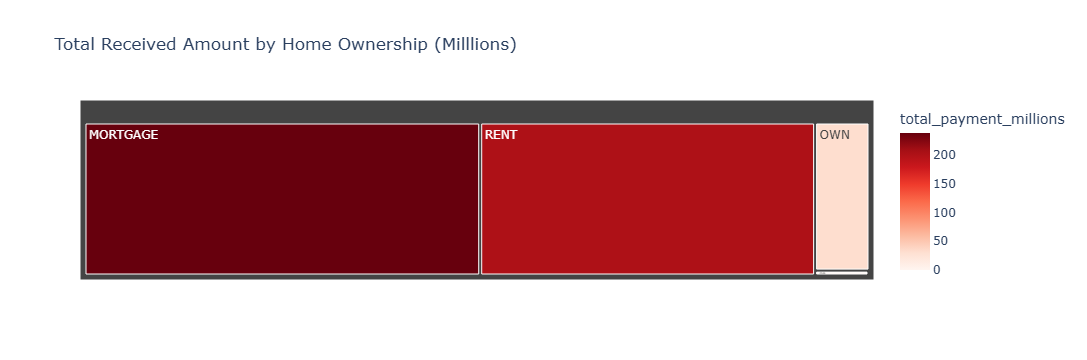

In [87]:
home_receiving = df.groupby('home_ownership')['total_payment'].sum().reset_index()
home_receiving['total_payment_millions'] = home_receiving['total_payment']/1000000

fig = px.treemap(
    home_receiving,
    path=['home_ownership'],
    values='total_payment_millions',
    color='total_payment_millions',
    color_continuous_scale='Reds',
    title='Total Received Amount by Home Ownership (Milllions)'
)
fig.show()

## Home Ownership by Total Loan Applications

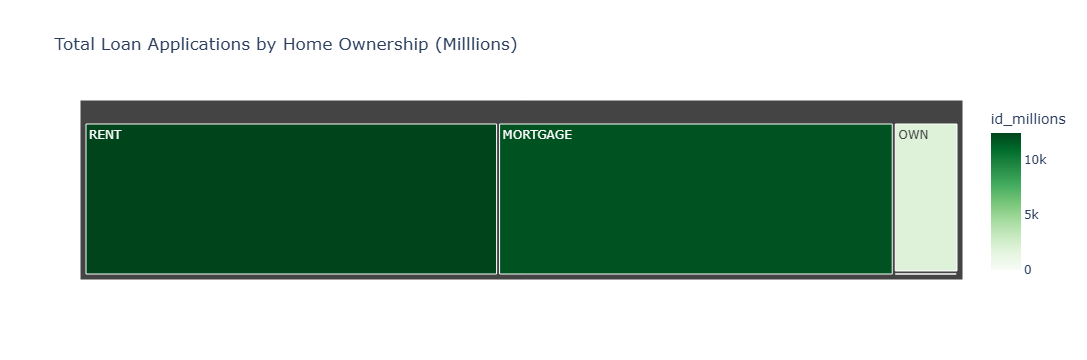

In [90]:
home_apps = df.groupby('home_ownership')['id'].sum().reset_index()
home_apps['id_millions'] = home_apps['id']/1000000

fig = px.treemap(
    home_apps,
    path=['home_ownership'],
    values='id_millions',
    color='id_millions',
    color_continuous_scale='Greens',
    title='Total Loan Applications by Home Ownership (Milllions)'
)
fig.show()